# AnyCam — 04 · Step 6: does the hyperspectral model work on other cameras? (E1 + E2)

1. Re-train our Step 5 baseline (model A: ResNet18, 2x images, strong augmentation, all 204 bands) — ~25 min
2. Train three **camera-specific** models (drone MicaSense, Sentinel-2 satellite, phone RGB) — the "one model per camera" approach used today — ~25 min each
3. Test the 204-band model on **7 simulated cameras**, each: ideal / band drift / calibration+noise / both — ~15 min

Total ~2 h. Same setup: **Add Input → HyperLeaf2024 (trophy)**, **GPU T4 x2**, **Internet On**.
Best: **Save Version → Save & Run All**, then save to GitHub as `kaggle_runs/04_step6_camera_test.ipynb`.

In [1]:
import os, subprocess, glob, json, pathlib
REPO = 'https://github.com/ShahnawazQ007/one-model-many-camera.git'
if not os.path.exists('/kaggle/working/anycam'):
    subprocess.run(['git', 'clone', '-q', '--depth', '1', REPO, '/kaggle/working/anycam'], check=True)
else:
    subprocess.run(['git', '-C', '/kaggle/working/anycam', 'pull', '-q'], check=True)
os.chdir('/kaggle/working/anycam')
!pip -q install timm tifffile imagecodecs
import torch; print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE - turn on the GPU accelerator!')
hits = [os.path.dirname(f) for f in glob.glob('/kaggle/input/**/train.csv', recursive=True)
        if os.path.isdir(os.path.join(os.path.dirname(f), 'images'))]
assert hits, 'Add Input -> search hyperleaf -> the one with the trophy icon'
DATA = hits[0]; print('data:', DATA, '| images:', len(glob.glob(f'{DATA}/images/*.tiff')))

GPU: Tesla T4
data: /kaggle/input/competitions/HyperLeaf2024 | images: 2410


In [2]:
# 1) the 204-band baseline (model A from Step 5)
!python experiments/train_baseline.py --data {DATA} --split official --upscale 2 --aug strong --epochs 50 --patience 12 --out runs/A_hs204

device cuda | train 1410 val 180 test 820 leaves

model.safetensors: downloading bytes: ███▎                  | 6.98MB,  409kB/s  
model.safetensors: downloading bytes: ████████████████▋     | 35.6MB, 2.46MB/s  
model.safetensors: reconstructing file:  13%|▊     | 6.32MB / 46.8MB,  516kB/s  
model.safetensors: downloading bytes: ██████████████████████| 44.0MB, 4.07MB/s  
model.safetensors: reconstructing file: 100%|██████| 46.8MB / 46.8MB, 4.44MB/s  
model resnet18: 11.81M parameters
epoch  0 train 2.223 val 2.295 (83s)
epoch  1 train 1.774 val 1.710 (152s)
epoch  2 train 1.455 val 1.394 (222s)
epoch  3 train 1.211 val 1.446 (292s)
epoch  4 train 1.025 val 1.246 (359s)
epoch  5 train 0.864 val 1.304 (427s)
epoch  6 train 0.796 val 1.180 (494s)
epoch  7 train 0.707 val 1.263 (561s)
epoch  8 train 0.629 val 1.448 (626s)
epoch  9 train 0.608 val 1.166 (693s)
epoch 10 train 0.558 val 1.305 (759s)
epoch 11 train 0.522 val 1.263 (826s)
epoch 12 train 0.491 val 1.405 (892s)
epoch 13 train 0.4

In [3]:
# 2) camera-specific models: trained and tested on the same simulated camera
for cam in ['micasense_rededge_mx', 'sentinel2a_vnir', 'generic_rgb']:
    !python experiments/train_baseline.py --data {DATA} --split official --camera {cam} --upscale 2 --aug strong --epochs 50 --patience 12 --out runs/oracle_{cam}

device cuda | train 1410 val 180 test 820 leaves
model resnet18: 11.19M parameters
epoch  0 train 2.196 val 2.005 (44s)
epoch  1 train 1.770 val 1.923 (82s)
epoch  2 train 1.510 val 1.628 (120s)
epoch  3 train 1.276 val 1.566 (157s)
epoch  4 train 1.070 val 1.394 (195s)
epoch  5 train 0.942 val 1.295 (233s)
epoch  6 train 0.814 val 1.151 (270s)
epoch  7 train 0.747 val 1.324 (307s)
epoch  8 train 0.677 val 1.324 (343s)
epoch  9 train 0.656 val 1.021 (379s)
epoch 10 train 0.583 val 1.305 (413s)
epoch 11 train 0.583 val 1.184 (448s)
epoch 12 train 0.544 val 1.063 (484s)
epoch 13 train 0.527 val 1.384 (519s)
epoch 14 train 0.488 val 1.054 (554s)
epoch 15 train 0.465 val 1.188 (589s)
epoch 16 train 0.444 val 1.083 (625s)
epoch 17 train 0.405 val 0.871 (660s)
epoch 18 train 0.425 val 1.172 (695s)
epoch 19 train 0.402 val 1.096 (730s)
epoch 20 train 0.392 val 1.026 (765s)
epoch 21 train 0.362 val 1.227 (801s)
epoch 22 train 0.351 val 1.425 (836s)
epoch 23 train 0.350 val 1.177 (870s)
epoch 2

hyperspectral_204        nominal      cultivar 0.821  fertilizer R2 +0.759  grain R2 +0.584  (21s)
hyperspectral_204        radiometric  cultivar 0.766  fertilizer R2 +0.679  grain R2 +0.498  (80s)
dji_p4_multispectral     nominal      cultivar 0.588  fertilizer R2 +0.206  grain R2 +0.079  (135s)
dji_p4_multispectral     drift        cultivar 0.563  fertilizer R2 +0.167  (mean of 3 units, 299s)
dji_p4_multispectral     radiometric  cultivar 0.549  fertilizer R2 -0.127  grain R2 -0.278  (365s)
dji_p4_multispectral     drift+radio  cultivar 0.517  fertilizer R2 -0.203  grain R2 -0.221  (431s)
generic_rgb              nominal      cultivar 0.360  fertilizer R2 +0.297  grain R2 +0.142  (486s)
generic_rgb              drift        cultivar 0.359  fertilizer R2 +0.289  (mean of 3 units, 648s)
generic_rgb              radiometric  cultivar 0.365  fertilizer R2 +0.255  grain R2 +0.092  (714s)
generic_rgb              drift+radio  cultivar 0.366  fertilizer R2 +0.240  grain R2 +0.064  (779s)
ge

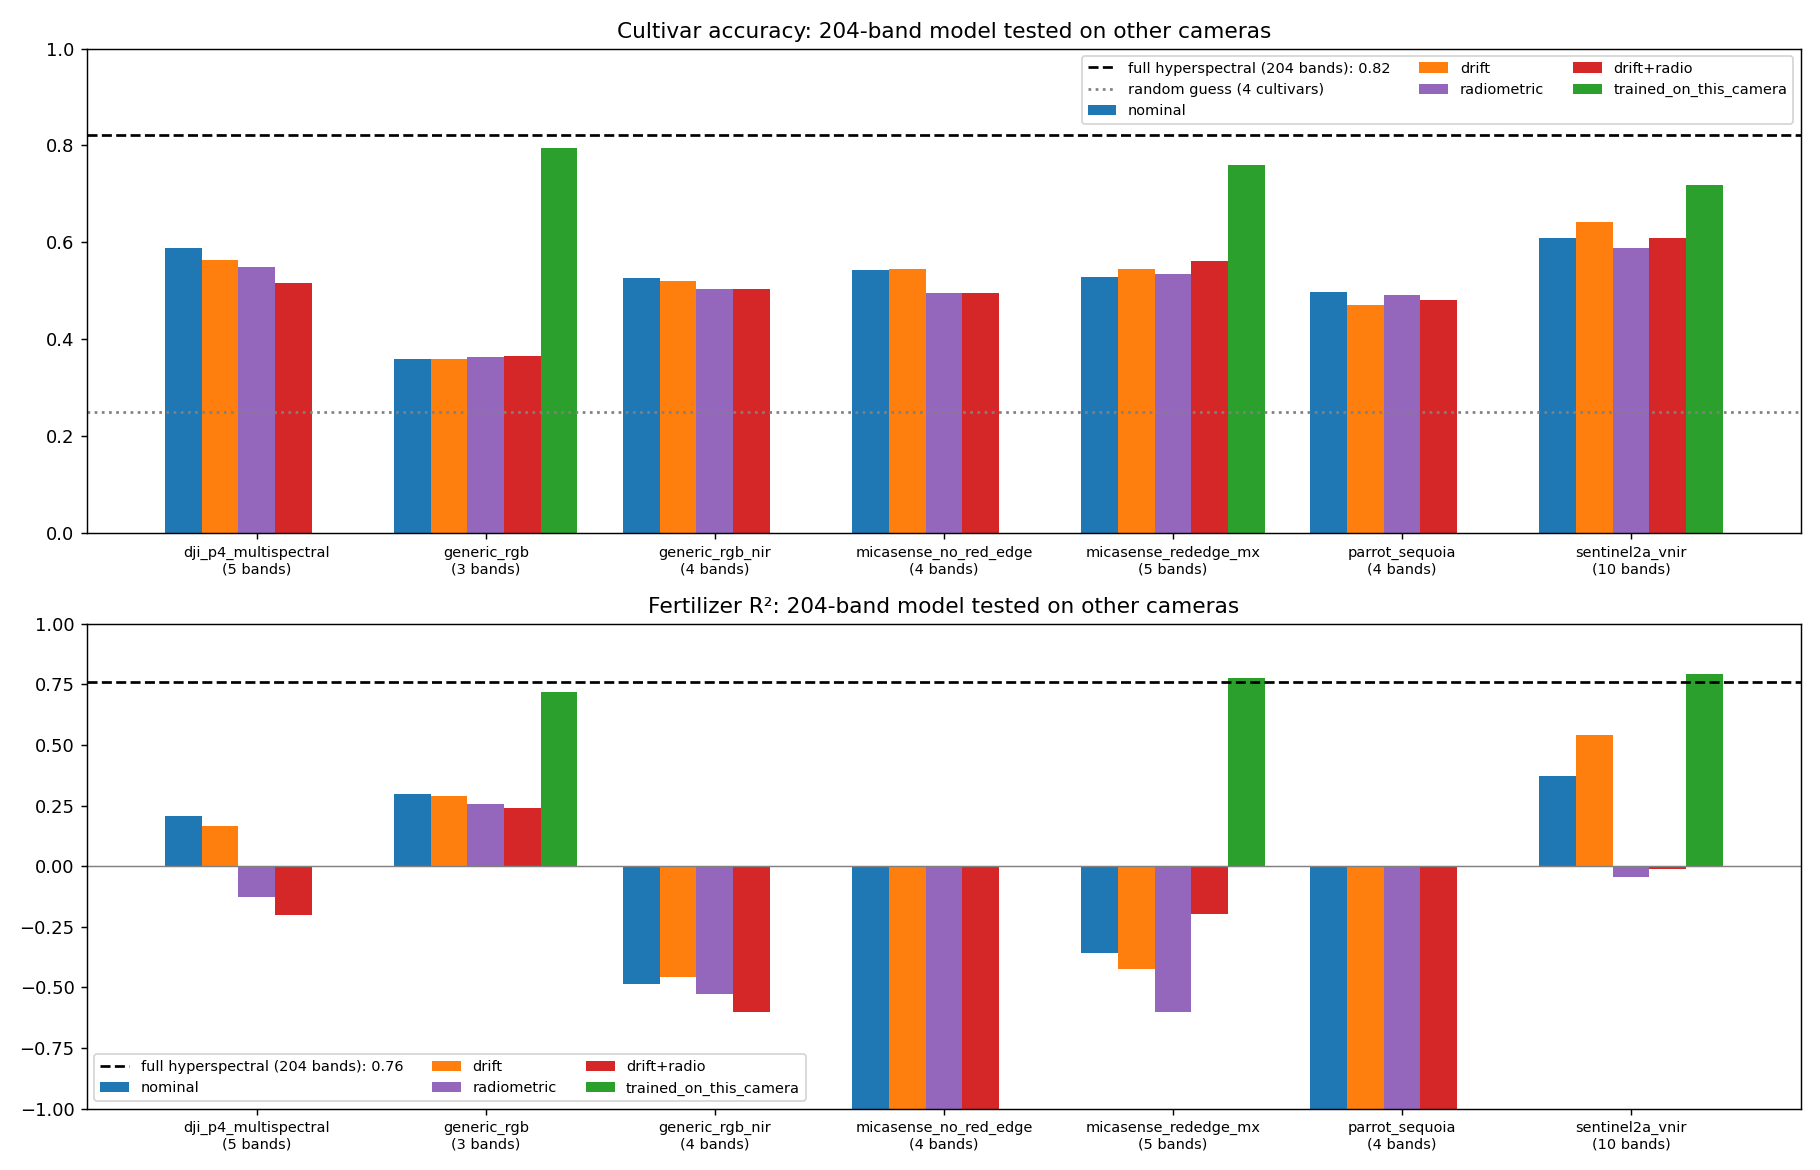

In [4]:
# 3) test the 204-band model on all 7 cameras (+ calibration errors) and draw the figure
!python experiments/eval_cameras.py --data {DATA} --run runs/A_hs204 --oracles "runs/oracle_*" --out runs/step6_eval
from IPython.display import Image, display
display(Image('runs/step6_eval/camera_eval.png'))

## Done
When every cell has finished: **GitHub → file** `kaggle_runs/04_step6_camera_test.ipynb` → **Save**. Tell Claude "done".